# Predicción del puntaje global de la prueba Saber 11: visualizaciones y narrativa de datos

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos**

---

**Actividad:** Proyecto Integrador de Ciencia de Datos | Fase 4 · Actividad 7: *Visualizaciones y narrativa de datos*, insumo del informe técnico final y de la sustentación (**Entregable 4**).

**Caso de estudio:** *Resultados únicos Saber 11*, ICFES, periodo **2022-4**, desde la copia congelada en Kaggle [`andyrubiano/saber-11-resultados-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-resultados-2022-4) (CC BY-SA 4.0).

**Punto de partida:** el conjunto limpio y la partición de la fase 2, y los modelos, métricas, importancias y predicciones de la fase 3 (cuadernos `02` y `03`).

**Producto de este cuaderno:** las figuras finales del proyecto, pensadas para sostener una narrativa en cinco actos (la desigualdad, su geografía, cuánto se puede predecir, qué pesa y para quién falla el modelo), la tabla resumen de resultados y el guion de mensajes clave para la sustentación.

## 1. Objetivo y principios de las visualizaciones

Este cuaderno cubre la parte de **comunicación** del objetivo específico 5: diseñar visualizaciones claras que respalden las conclusiones del proyecto. Las fases anteriores produjeron más de veinte figuras de trabajo; aquí se construyen las pocas que contarán la historia en el informe y en la sustentación, con cinco principios:

1.  **Una idea por figura.** Cada gráfica responde una sola pregunta, escrita en su título.
2.  **Puntos de la escala como unidad común.** Todas las brechas, errores y contribuciones se expresan en puntos del puntaje global (0 a 500), para que el lector compare sin convertir.
3.  **Colores por concepto, no por orden.** Azul para el modelo principal y los grupos de referencia, naranja para contrastes y alertas, verde para el *random forest*, gris para lo ingenuo; igual que en los cuadernos anteriores.
4.  **Anotaciones en la figura.** Las cifras decisivas van escritas sobre la gráfica, no solo en el texto.
5.  **Honestidad con los límites.** Las figuras muestran también lo que el modelo no logra, porque esa es una de las conclusiones del proyecto.

La narrativa sigue el orden del proyecto: primero el problema (la desigualdad del puntaje), luego su geografía, después cuánto se puede predecir, qué variables pesan y, al final, para quién falla el modelo y qué se debe y no se debe hacer con él.

## 2. Preparación del entorno

Las mismas librerías e identidad gráfica de los cuadernos anteriores. `scikit-learn`, `kagglehub` y `joblib` solo se usan si hay que reconstruir los artefactos.

In [1]:
import os, sys, time, warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__, "| seaborn:", sns.__version__)

IN_COLAB = "google.colab" in sys.modules

def find_project_root(start=Path.cwd()):
    """Sube por el árbol de carpetas hasta encontrar la raíz del repositorio (README.md + notebooks/)."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "assets" / "images" / "data"
for folder in (PROCESSED_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print(f"Entorno          : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | matplotlib: 3.11.2 | seaborn: 0.13.2
Entorno          : local
Raíz del proyecto: D:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


In [2]:
C_BASE, C_ACCENT, C_NEU = "#2a78d6", "#eb6834", "#5B7C99"
C_HGB, C_RF, C_RIDGE, C_MEDIA = "#2a78d6", "#2CA02C", "#eb6834", "#7F7F7F"
TINTA, GRIS, CLARO = "#0b0b0b", "#52514e", "#d9d8d3"
BLOQUE_COLOR = {"Hogar": "#2a78d6", "Colegio": "#eb6834", "Estudiante": "#9467BD", "Geografía": "#2CA02C"}

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": CLARO, "axes.labelcolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "font.size": 10, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "grid.color": "#eeede9", "grid.linewidth": 0.8,
})
RANDOM_STATE = 42

def save_fig(fig, name):
    """Guarda la figura en assets/images/data/<name>.png (160 dpi para el informe y la sustentación)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

def miles(v, _=None):
    return f"{v / 1000:g} k"

## 3. Artefactos de las fases 2 y 3

Se cargan el conjunto limpio, la partición, las predicciones de los cuatro modelos sobre el conjunto de prueba, la tabla de métricas, las importancias por permutación y SHAP, y los resultados de las búsquedas. Si falta alguno (una sesión nueva de Colab), la celda reconstruye lo mínimo necesario desde Kaggle con el mismo código y los hiperparámetros elegidos en la fase 3: prepara los datos, ajusta Ridge y el boosting, y recalcula predicciones, métricas e importancia por permutación. El *random forest* y los valores SHAP no se reconstruyen por su costo; en ese caso las figuras que los usan lo indican.

In [3]:
NECESARIOS = ["saber11_fase2.parquet", "particion.parquet", "columnas.json", "predicciones_fase3.parquet",
              "metricas_fase3.csv", "importancias.csv", "shap_importancia.csv"]
faltan = [a for a in NECESARIOS if not (PROCESSED_DIR / a).exists()]
RECONSTRUIDO = bool(faltan)

if RECONSTRUIDO:
    print(f"Artefactos no encontrados ({faltan}); reconstrucción mínima desde Kaggle ...")
    import kagglehub, sklearn
    from sklearn.model_selection import train_test_split
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import HistGradientBoostingRegressor
    from sklearn.inspection import permutation_importance
    from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
    t0 = time.time()
    raw = pd.read_parquet(kagglehub.dataset_download("andyrubiano/saber-11-resultados-2022-4", path="saber11_20224.parquet"))
    d = raw.drop_duplicates().reset_index(drop=True).set_index("estu_consecutivo")
    d = d.drop(columns=["punt_lectura_critica", "punt_matematicas", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles",
                        "desemp_ingles", "periodo", "estu_estudiante", "estu_estadoinvestigacion", "estu_privado_libertad",
                        "cole_cod_dane_establecimiento", "cole_cod_dane_sede", "cole_codigo_icfes", "cole_nombre_establecimiento",
                        "cole_nombre_sede", "cole_cod_depto_ubicacion", "cole_cod_mcpio_ubicacion", "estu_cod_depto_presentacion",
                        "estu_cod_mcpio_presentacion", "estu_depto_presentacion", "estu_mcpio_presentacion", "estu_cod_reside_depto",
                        "estu_cod_reside_mcpio", "estu_depto_reside", "estu_mcpio_reside", "estu_nacionalidad", "estu_pais_reside",
                        "estu_tipodocumento"])
    nac = pd.to_datetime(d["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
    d["edad"] = ((pd.Timestamp("2022-09-04") - nac).dt.days / 365.25).round(1)
    d.loc[(d["edad"] < 13) | (d["edad"] > 80), "edad"] = np.nan
    d["edad"] = d["edad"].fillna(d["edad"].median()); d["extraedad"] = (d["edad"] >= 19).astype("int8")
    d = d.drop(columns=["estu_fechanacimiento"])
    fami = [c for c in d.columns if c.startswith("fami_")]
    d["cuestionario_incompleto"] = d[fami].isna().any(axis=1).astype("int8")
    for col, et in [(c, "No respondió") for c in fami] + [("cole_bilingue", "No reportado"), ("cole_caracter", "No reportado")]:
        d[col] = d[col].cat.add_categories([et]).fillna(et)
    for col in d.columns[d.isna().any()]:
        d[col] = d[col].fillna(d[col].mode().iloc[0])
    edu = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
           "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
           "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
    for p, col in [("madre", "fami_educacionmadre"), ("padre", "fami_educacionpadre")]:
        o = d[col].astype(object).map(edu); d[f"educ_{p}_ord"] = o.astype("float32"); d[f"educ_{p}_desconocida"] = o.isna().astype("int8")
    per = d["fami_personashogar"].astype(object).map({"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5})
    cua = d["fami_cuartoshogar"].astype(object).map({"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6})
    d["personas_por_cuarto"] = (per / cua).astype("float32"); d["genero_F"] = (d["estu_genero"] == "F").astype("int8")
    d["naturaleza_area"] = (d["cole_naturaleza"].astype(str) + " · " + d["cole_area_ubicacion"].astype(str)).astype("category")
    d = d.drop(columns=["estu_genero", "fami_educacionmadre", "fami_educacionpadre"])
    cols = {"NUM_COLS": ["edad", "educ_madre_ord", "educ_padre_ord", "personas_por_cuarto"],
            "BIN_COLS": ["extraedad", "cuestionario_incompleto", "educ_madre_desconocida", "educ_padre_desconocida", "genero_F"],
            "NOM_COLS": ["fami_estratovivienda", "fami_personashogar", "fami_cuartoshogar", "fami_tieneinternet", "fami_tienecomputador",
                         "fami_tieneautomovil", "fami_tienelavadora", "cole_naturaleza", "cole_area_ubicacion", "naturaleza_area",
                         "cole_jornada", "cole_caracter", "cole_calendario", "cole_genero", "cole_sede_principal", "cole_bilingue",
                         "cole_depto_ubicacion"], "HIGH_CARD_COLS": ["cole_mcpio_ubicacion"], "TARGET": "punt_global"}
    for c in cols["NOM_COLS"] + cols["HIGH_CARD_COLS"]:
        d[c] = d[c].astype("category").cat.remove_unused_categories()
    deciles = pd.qcut(d["punt_global"], q=10, labels=False).to_numpy(); pos = np.arange(len(d))
    p_tr, p_tmp = train_test_split(pos, test_size=0.30, random_state=RANDOM_STATE, stratify=deciles)
    p_va, p_te = train_test_split(p_tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=deciles[p_tmp])
    part = pd.Series("train", index=d.index, name="particion"); part.iloc[p_va] = "val"; part.iloc[p_te] = "test"
    d.to_parquet(PROCESSED_DIR / "saber11_fase2.parquet"); part.astype("category").to_frame().to_parquet(PROCESSED_DIR / "particion.parquet")
    json.dump(cols, open(PROCESSED_DIR / "columnas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    feats = cols["NUM_COLS"] + cols["BIN_COLS"] + cols["NOM_COLS"] + cols["HIGH_CARD_COLS"]
    Xtr, ytr = d.loc[part == "train", feats], d.loc[part == "train", "punt_global"]
    Xte, yte = d.loc[part == "test", feats], d.loc[part == "test", "punt_global"]
    pl = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), cols["NUM_COLS"]),
                            ("bin", "passthrough", cols["BIN_COLS"]),
                            ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), cols["NOM_COLS"]),
                            ("mcpio", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), cols["HIGH_CARD_COLS"])],
                           verbose_feature_names_out=False).set_output(transform="pandas").fit(Xtr, ytr)
    pa = ColumnTransformer([("num", "passthrough", cols["NUM_COLS"]), ("bin", "passthrough", cols["BIN_COLS"]),
                            ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1, dtype=np.float32), cols["NOM_COLS"]),
                            ("mcpio", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), cols["HIGH_CARD_COLS"])],
                           verbose_feature_names_out=False).set_output(transform="pandas").fit(Xtr, ytr)
    mask = [c in cols["NOM_COLS"] for c in pa.get_feature_names_out()]
    ridge = Ridge(alpha=0.01).fit(pl.transform(Xtr), ytr)
    MEJOR_HGB = {"learning_rate": 0.1, "max_iter": 400, "max_leaf_nodes": 15, "min_samples_leaf": 100, "l2_regularization": 5.0}
    hgb = HistGradientBoostingRegressor(**MEJOR_HGB, categorical_features=mask, early_stopping=False, random_state=RANDOM_STATE).fit(pa.transform(Xtr), ytr)
    Xa_te = pa.transform(Xte)
    pred = pd.DataFrame({"y_real": yte, "pred_media": ytr.mean(), "pred_ridge": ridge.predict(pl.transform(Xte)),
                         "pred_gradient": hgb.predict(Xa_te)}, index=yte.index)
    pred.to_parquet(PROCESSED_DIR / "predicciones_fase3.parquet")
    filas = {}
    for nombre, col in [("Media (ingenuo)", "pred_media"), ("Ridge (referencia)", "pred_ridge"), ("Gradient boosting", "pred_gradient")]:
        filas[(nombre, "test")] = {"MAE": mean_absolute_error(yte, pred[col]), "RMSE": root_mean_squared_error(yte, pred[col]), "R2": r2_score(yte, pred[col])}
    met = pd.DataFrame(filas).T; met.index.names = ["modelo", "parte"]; met.to_csv(PROCESSED_DIR / "metricas_fase3.csv")
    sel = np.random.default_rng(RANDOM_STATE).choice(len(Xa_te), 5_000, replace=False)
    pi = permutation_importance(hgb, Xa_te.iloc[sel], yte.iloc[sel], scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE)
    imp = pd.DataFrame({"Gradient boosting": pi.importances_mean}, index=pa.get_feature_names_out()); imp.to_csv(PROCESSED_DIR / "importancias.csv")
    imp["Gradient boosting"].rename("0").to_csv(PROCESSED_DIR / "shap_importancia.csv")
    joblib.dump(hgb, MODELS_DIR / "hgb.joblib"); joblib.dump(ridge, MODELS_DIR / "baseline_ridge.joblib")
    print(f"Reconstrucción completa en {time.time() - t0:.0f} s (sin random forest ni SHAP)")
else:
    print("Artefactos de las fases 2 y 3 encontrados; se reutilizan.")

df = pd.read_parquet(PROCESSED_DIR / "saber11_fase2.parquet")
particion = pd.read_parquet(PROCESSED_DIR / "particion.parquet")["particion"]
COLS = json.load(open(PROCESSED_DIR / "columnas.json", encoding="utf-8"))
pred = pd.read_parquet(PROCESSED_DIR / "predicciones_fase3.parquet")
metricas = pd.read_csv(PROCESSED_DIR / "metricas_fase3.csv", index_col=[0, 1])
importancias = pd.read_csv(PROCESSED_DIR / "importancias.csv", index_col=0)
shap_imp = pd.read_csv(PROCESSED_DIR / "shap_importancia.csv", index_col=0).iloc[:, 0]
TIENE_RF = "Random forest" in metricas.index.get_level_values(0)
TIENE_SHAP = not RECONSTRUIDO
print(f"Estudiantes: {len(df):,} | prueba: {len(pred):,} | modelos con métricas: {metricas.index.get_level_values(0).unique().tolist()}")

Artefactos de las fases 2 y 3 encontrados; se reutilizan.
Estudiantes: 532,792 | prueba: 79,919 | modelos con métricas: ['Media (ingenuo)', 'Ridge (referencia)', 'Gradient boosting', 'Random forest']


Los artefactos de las fases 2 y 3 estaban disponibles: 532.792 estudiantes, 79.919 en prueba con las predicciones de los cuatro modelos, y las importancias por permutación y SHAP. No hizo falta reconstruir nada, así que todas las figuras usan exactamente los resultados reportados en los cuadernos anteriores.

## 4. Acto 1 · La desigualdad del puntaje

La primera figura responde a la pregunta que abrió el proyecto: **¿cuánto cambia el puntaje según el contexto del estudiante?** Para cada variable se calcula el puntaje medio del grupo más favorecido y del menos favorecido (entre los grupos con al menos 1.000 estudiantes) y se dibuja la distancia entre ambos. Ordenadas de mayor a menor brecha, las barras muestran de un vistazo qué dimensiones del contexto separan más a los estudiantes, en puntos de la escala. Se usa el conjunto completo de 532.792 estudiantes, porque es descripción y no predicción.

Figura guardada: assets\images\data\story_1_gaps.png


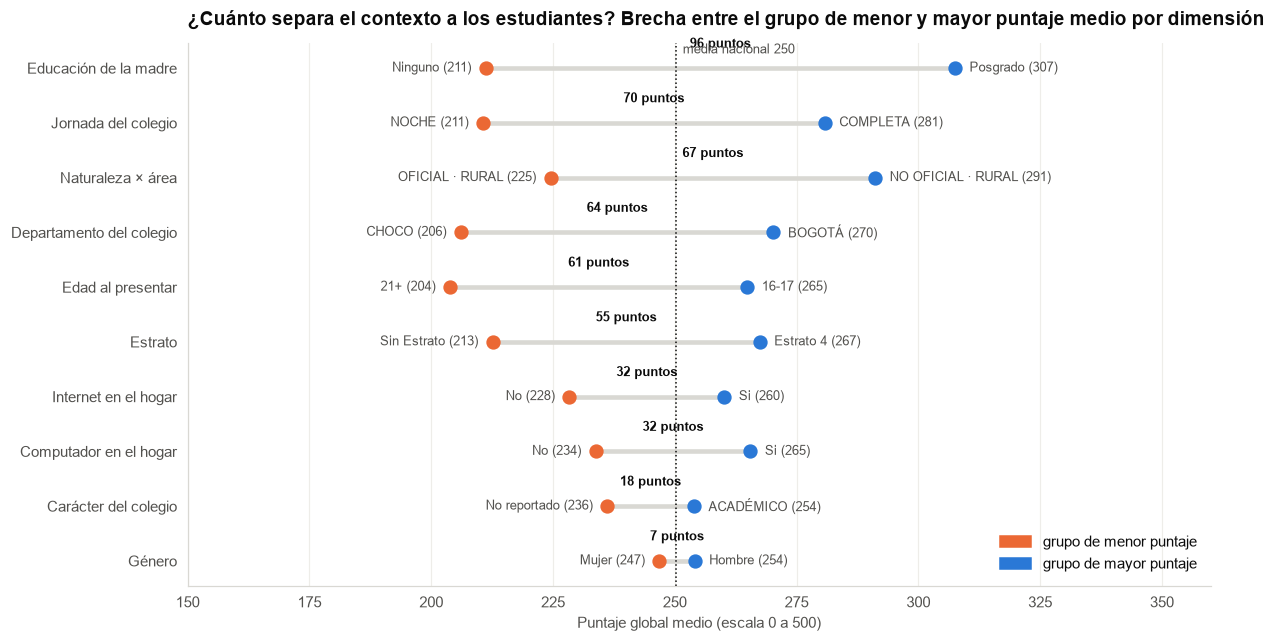

,bloque,grupo bajo,media baja,grupo alto,media alta,brecha
dimensión,,,,,,
Educación de la madre,Hogar,Ninguno,211.20,Posgrado,307.50,96.30
Jornada del colegio,Colegio,NOCHE,210.60,COMPLETA,280.80,70.10
Naturaleza × área,Colegio,OFICIAL · RURAL,224.50,NO OFICIAL · RURAL,291.10,66.60
Departamento del colegio,Geografía,CHOCO,206.10,BOGOTÁ,270.20,64.10
Edad al presentar,Estudiante,21+,203.90,16-17,264.90,61.00
Estrato,Hogar,Sin Estrato,212.60,Estrato 4,267.40,54.80
Internet en el hogar,Hogar,No,228.40,Si,260.20,31.80
Computador en el hogar,Hogar,No,233.80,Si,265.50,31.70
Carácter del colegio,Colegio,No reportado,236.10,ACADÉMICO,253.90,17.80


In [4]:
EDU = {0: "Ninguno", 1: "Primaria inc.", 2: "Primaria", 3: "Secundaria inc.", 4: "Secundaria", 5: "Técnica inc.",
       6: "Técnica", 7: "Profesional inc.", 8: "Profesional", 9: "Posgrado"}
desc = df.assign(educ_madre=df["educ_madre_ord"].map(EDU).fillna("No sabe / no respondió"),
                 tramo_edad=pd.cut(df["edad"], [0, 17, 18, 20, 100], labels=["16-17", "18", "19-20", "21+"]))
DIMENSIONES = [("Educación de la madre", "educ_madre", "Hogar"), ("Jornada del colegio", "cole_jornada", "Colegio"),
               ("Edad al presentar", "tramo_edad", "Estudiante"), ("Departamento del colegio", "cole_depto_ubicacion", "Geografía"),
               ("Naturaleza × área", "naturaleza_area", "Colegio"), ("Estrato", "fami_estratovivienda", "Hogar"),
               ("Internet en el hogar", "fami_tieneinternet", "Hogar"), ("Computador en el hogar", "fami_tienecomputador", "Hogar"),
               ("Carácter del colegio", "cole_caracter", "Colegio"), ("Género", "genero_F", "Estudiante")]
filas = []
for etiqueta, col, bloque in DIMENSIONES:
    g = desc.groupby(col, observed=True)["punt_global"].agg(["mean", "size"])
    g = g[g["size"] >= 1000]
    filas.append({"dimensión": etiqueta, "bloque": bloque, "grupo bajo": str(g["mean"].idxmin()), "media baja": g["mean"].min(),
                  "grupo alto": str(g["mean"].idxmax()), "media alta": g["mean"].max(), "brecha": g["mean"].max() - g["mean"].min()})
brechas = pd.DataFrame(filas).sort_values("brecha", ascending=True)
brechas["grupo alto"] = brechas["grupo alto"].replace({"1": "Mujer", "0": "Hombre"}); brechas["grupo bajo"] = brechas["grupo bajo"].replace({"1": "Mujer", "0": "Hombre"})
brechas.to_csv(PROCESSED_DIR / "brechas.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 6.4))
for i, r in enumerate(brechas.itertuples()):
    ax.plot([r._4, r._6], [i, i], color=CLARO, linewidth=3, zorder=1)
    ax.scatter(r._4, i, s=70, color=C_ACCENT, zorder=2); ax.scatter(r._6, i, s=70, color=C_BASE, zorder=2)
    ax.text(r._4 - 3, i, f"{r._3} ({r._4:.0f})", ha="right", va="center", fontsize=8.5, color=GRIS)
    ax.text(r._6 + 3, i, f"{r._5} ({r._6:.0f})", ha="left", va="center", fontsize=8.5, color=GRIS)
    ax.text((r._4 + r._6) / 2, i + 0.32, f"{r.brecha:.0f} puntos", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=TINTA)
ax.set_yticks(range(len(brechas))); ax.set_yticklabels(brechas["dimensión"], fontsize=10)
ax.set_xlim(150, 360); ax.set_xlabel("Puntaje global medio (escala 0 a 500)")
ax.axvline(df["punt_global"].mean(), color=TINTA, linestyle=":", linewidth=1)
ax.text(df["punt_global"].mean() + 1.5, len(brechas) - 0.55, f"media nacional {df['punt_global'].mean():.0f}", fontsize=8.5, color=GRIS, va="top")
ax.set_title("¿Cuánto separa el contexto a los estudiantes? Brecha entre el grupo de menor y mayor puntaje medio por dimensión")
ax.legend(handles=[Patch(color=C_ACCENT, label="grupo de menor puntaje"), Patch(color=C_BASE, label="grupo de mayor puntaje")],
          frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "story_1_gaps")
plt.show()
display(brechas.sort_values("brecha", ascending=False).round(1).set_index("dimensión"))

La figura ordena las dimensiones del contexto por la distancia entre su grupo de menor y mayor puntaje. La **educación de la madre** encabeza la lista con **96 puntos** entre *Ninguno* (211) y *Posgrado* (307), casi dos desviaciones estándar del puntaje. Le siguen la **jornada** (70 puntos entre nocturna y completa), la combinación **naturaleza × área** (67 puntos, con los colegios privados rurales en la cima y los oficiales rurales en la base), el **departamento** (64 puntos entre Chocó y Bogotá) y la **edad** (61 puntos entre los mayores de 21 y los de 16 y 17). El estrato (55), internet (32) y computador (32) completan el bloque del hogar; el carácter del colegio (18) y el género (7) son las dimensiones con menos separación.

Todas las brechas cruzan la media nacional de 250: en cada dimensión hay un grupo claramente por encima y otro claramente por debajo. Esa es la desigualdad que el proyecto se propuso cuantificar, y la razón por la que el contexto permite predecir una parte del puntaje.

## 5. Acto 2 · La geografía de la brecha

La segunda figura cruza dos cosas que la fase 1 presentó por separado: el puntaje medio de cada departamento y la proporción de sus estudiantes con internet en el hogar, un indicador directo del nivel socioeconómico del entorno. Cada burbuja es un departamento y su tamaño, el número de estudiantes. Si la brecha regional fuera solo reflejo de la brecha socioeconómica, los puntos se alinearían sobre una recta; los que se alejan de ella son los departamentos que rinden más o menos de lo que su contexto predice.

Figura guardada: assets\images\data\story_2_geography.png


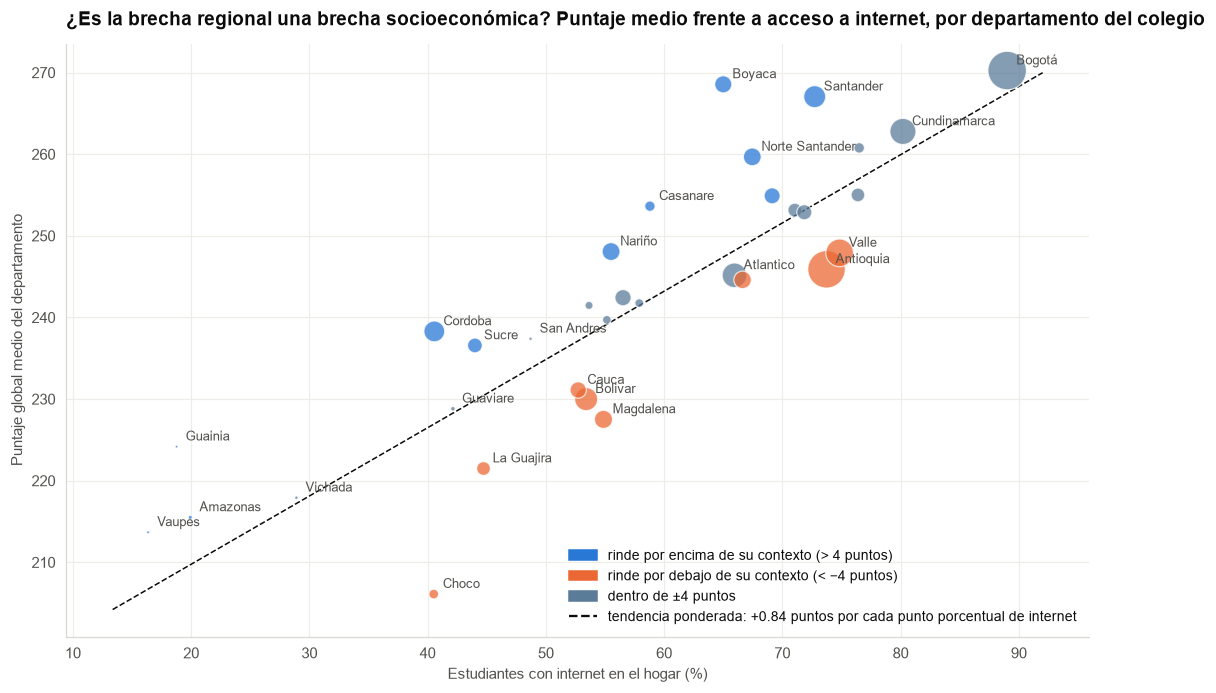

Correlación entre acceso a internet y puntaje medio departamental: 0.86


cole_depto_ubicacion,CHOCO,MAGDALENA,LA GUAJIRA,ANTIOQUIA,CASANARE,SANTANDER,GUAINIA,BOYACA
puntaje,206.10,227.50,221.50,245.90,253.60,267.00,224.20,268.60
internet,40.50,54.90,44.70,73.70,58.80,72.70,18.80,65.00
n,"4,818.00","16,865.00","9,775.00","72,383.00","5,529.00","24,884.00",389.00,"15,072.00"
residuo,-20.80,-11.40,-9.00,-8.80,11.40,13.20,15.40,21.20


In [5]:
geo = (df.assign(internet=(df["fami_tieneinternet"] == "Si").astype(float))
         .groupby("cole_depto_ubicacion", observed=True)
         .agg(puntaje=("punt_global", "mean"), internet=("internet", "mean"), n=("punt_global", "size"))
         .assign(internet=lambda d: d["internet"] * 100))
pend, inter = np.polyfit(geo["internet"], geo["puntaje"], 1, w=np.sqrt(geo["n"]))
geo["residuo"] = geo["puntaje"] - (pend * geo["internet"] + inter)
geo.to_csv(PROCESSED_DIR / "geografia.csv")

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(geo["internet"], geo["puntaje"], s=geo["n"] / 120, color=[C_ACCENT if r < -4 else (C_BASE if r > 4 else C_NEU) for r in geo["residuo"]],
           alpha=0.75, edgecolors="white", linewidths=0.8, zorder=2)
xs = np.linspace(geo["internet"].min() - 3, geo["internet"].max() + 3, 50)
ax.plot(xs, pend * xs + inter, color=TINTA, linestyle="--", linewidth=1, zorder=1,
        label=f"tendencia ponderada: +{pend:.2f} puntos por cada punto porcentual de internet")
for nombre, r in geo.iterrows():
    if r["n"] > 30000 or abs(r["residuo"]) > 6 or r["internet"] < 50:
        ax.annotate(nombre.title(), (r["internet"], r["puntaje"]), textcoords="offset points", xytext=(6, 4), fontsize=8.5, color=GRIS)
ax.set_xlabel("Estudiantes con internet en el hogar (%)"); ax.set_ylabel("Puntaje global medio del departamento")
ax.set_title("¿Es la brecha regional una brecha socioeconómica? Puntaje medio frente a acceso a internet, por departamento del colegio")
ax.legend(handles=[Patch(color=C_BASE, label="rinde por encima de su contexto (> 4 puntos)"),
                   Patch(color=C_ACCENT, label="rinde por debajo de su contexto (< −4 puntos)"),
                   Patch(color=C_NEU, label="dentro de ±4 puntos"), plt.Line2D([], [], color=TINTA, linestyle="--", label=ax.get_legend_handles_labels()[1][0])],
          frameon=False, loc="lower right", fontsize=9)
save_fig(fig, "story_2_geography")
plt.show()
print(f"Correlación entre acceso a internet y puntaje medio departamental: {np.corrcoef(geo['internet'], geo['puntaje'])[0, 1]:.2f}")
display(geo.sort_values("residuo").round(1).iloc[np.r_[0:4, -4:0]].T)

La correlación entre el acceso a internet y el puntaje medio departamental es de **0,86**: en buena medida la brecha regional es una brecha socioeconómica. La tendencia ponderada indica **0,84 puntos de puntaje por cada punto porcentual** de hogares con internet, de modo que los 70 puntos porcentuales que separan a Guainía (19 %) de Bogotá (89 %) equivalen por sí solos a unos 60 puntos de puntaje.

Pero la recta no lo explica todo, y los residuos son el hallazgo de la figura. **Boyacá (+21), Guainía (+15), Santander (+13) y Casanare (+11)** rinden por encima de lo que su acceso a internet predice; **Chocó (−21), Magdalena (−11), La Guajira (−9) y Antioquia (−9)** rinden por debajo. Chocó es el caso más llamativo: con el 40 % de hogares conectados, similar a Córdoba o Sucre, obtiene 30 puntos menos que ellos. Antioquia y Valle, con mucho acceso y muchos estudiantes, también quedan por debajo de la recta, mientras Boyacá, con acceso medio, es el segundo departamento del país. Hay algo en los sistemas educativos regionales que el nivel socioeconómico no captura, y es justamente lo que la variable de municipio aporta al modelo.

## 6. Acto 3 · Cuánto se puede predecir

La tercera figura reúne la respuesta cuantitativa del proyecto en dos paneles. A la izquierda, el error absoluto medio y el R² de los cuatro modelos en prueba, con la mejora respecto de la media ingenua anotada. A la derecha, la **calibración por decil**: se ordenan los estudiantes de prueba por su puntaje real, se agrupan en diez deciles y se compara el puntaje real medio de cada decil con el que predice el boosting. La distancia a la diagonal muestra la compresión hacia la media que limita a todos los modelos.

Figura guardada: assets\images\data\story_3_prediction.png


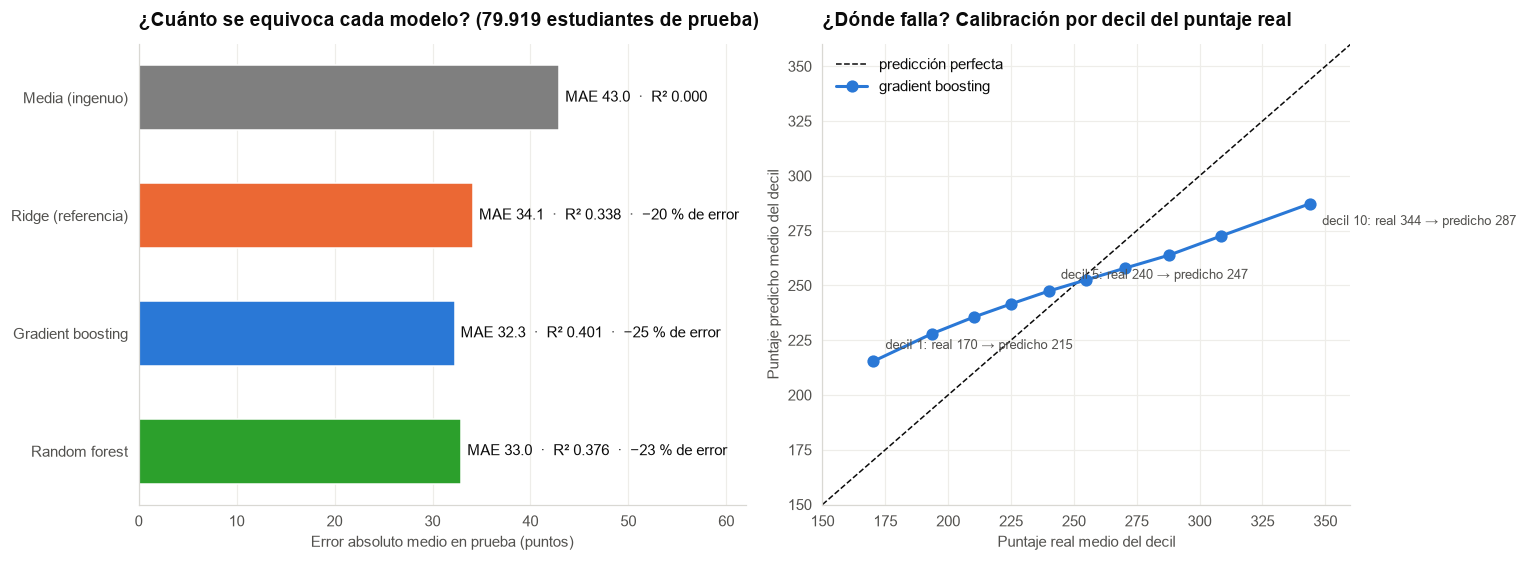

,Ridge,Gradient boosting
dentro de ±25 puntos (%),42.80,45.80
dentro de ±50 puntos (%),75.60,78.50


In [6]:
prueba = metricas.xs("test", level=1)
orden = [m for m in ["Media (ingenuo)", "Ridge (referencia)", "Gradient boosting", "Random forest"] if m in prueba.index]
prueba = prueba.loc[orden]
colores = {"Media (ingenuo)": C_MEDIA, "Ridge (referencia)": C_RIDGE, "Gradient boosting": C_HGB, "Random forest": C_RF}
mae_media = prueba.loc["Media (ingenuo)", "MAE"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
y = np.arange(len(prueba))
bars = axes[0].barh(y, prueba["MAE"], color=[colores[m] for m in prueba.index], height=0.55)
for yi, (m, r) in zip(y, prueba.iterrows()):
    mejora = (1 - r["MAE"] / mae_media) * 100
    axes[0].text(r["MAE"] + 0.6, yi, f"MAE {r['MAE']:.1f}  ·  R² {r['R2']:.3f}" + (f"  ·  −{mejora:.0f} % de error" if mejora > 0 else ""),
                 va="center", fontsize=9.5)
axes[0].set_yticks(y); axes[0].set_yticklabels(prueba.index, fontsize=10); axes[0].invert_yaxis()
axes[0].set_xlim(0, 62); axes[0].set_xlabel("Error absoluto medio en prueba (puntos)")
axes[0].set_title("¿Cuánto se equivoca cada modelo? (79.919 estudiantes de prueba)"); axes[0].grid(axis="y", visible=False)

dec = pred.assign(decil=pd.qcut(pred["y_real"], 10, labels=False) + 1).groupby("decil").agg(real=("y_real", "mean"), pred=("pred_gradient", "mean"))
axes[1].plot([150, 360], [150, 360], color=TINTA, linestyle="--", linewidth=1, label="predicción perfecta")
axes[1].plot(dec["real"], dec["pred"], marker="o", color=C_HGB, linewidth=2, markersize=7, label="gradient boosting")
for d, r in dec.iterrows():
    if d in (1, 5, 10):
        axes[1].annotate(f"decil {d}: real {r['real']:.0f} → predicho {r['pred']:.0f}", (r["real"], r["pred"]),
                         textcoords="offset points", xytext=(8, -14 if d == 10 else 8), fontsize=8.5, color=GRIS)
axes[1].set_xlim(150, 360); axes[1].set_ylim(150, 360)
axes[1].set_xlabel("Puntaje real medio del decil"); axes[1].set_ylabel("Puntaje predicho medio del decil")
axes[1].set_title("¿Dónde falla? Calibración por decil del puntaje real"); axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "story_3_prediction")
plt.show()
dentro = {m: [(pred["y_real"] - pred[c]).abs().le(25).mean() * 100, (pred["y_real"] - pred[c]).abs().le(50).mean() * 100]
          for m, c in [("Ridge", "pred_ridge"), ("Gradient boosting", "pred_gradient")]}
display(pd.DataFrame(dentro, index=["dentro de ±25 puntos (%)", "dentro de ±50 puntos (%)"]).round(1))

El panel izquierdo resume la fase 3: el **gradient boosting reduce el error de predecir la media en un 25 %** (de 43 a 32,3 puntos) y explica el 40 % de la variación del puntaje; Ridge lo reduce un 20 % y el *random forest* un 23 %. El 45,8 % de los estudiantes queda a 25 puntos o menos de su puntaje real y el 78,5 % a 50 o menos.

El panel derecho muestra el límite. La curva de calibración es una recta de pendiente menor que la diagonal: el decil más bajo tiene un puntaje real medio de **170 y el modelo predice 215**; el decil más alto tiene **344 y el modelo predice 287**. El modelo acierta en el centro (decil 5: 240 real, 247 predicho) y comprime los extremos unos 45 a 55 puntos. No es un defecto del algoritmo sino de la información: las variables de contexto describen al estudiante típico de cada situación, y los estudiantes excepcionales, por arriba o por abajo, se alejan de ese típico.

## 7. Acto 4 · Qué pesa

La cuarta figura responde **qué variables explican la predicción**, combinando los dos métodos de la fase 3 que resultaron consistentes: la importancia por permutación y el valor SHAP medio absoluto del boosting. Para que se lean juntos, cada uno se normaliza respecto de su máximo. Las variables se colorean por bloque (hogar, colegio, estudiante, geografía) y el panel derecho suma la contribución SHAP por bloque, que es la respuesta a la hipótesis H1 del proyecto: ¿pesa más el hogar, el colegio, el estudiante o el territorio?

Figura guardada: assets\images\data\story_4_importance.png


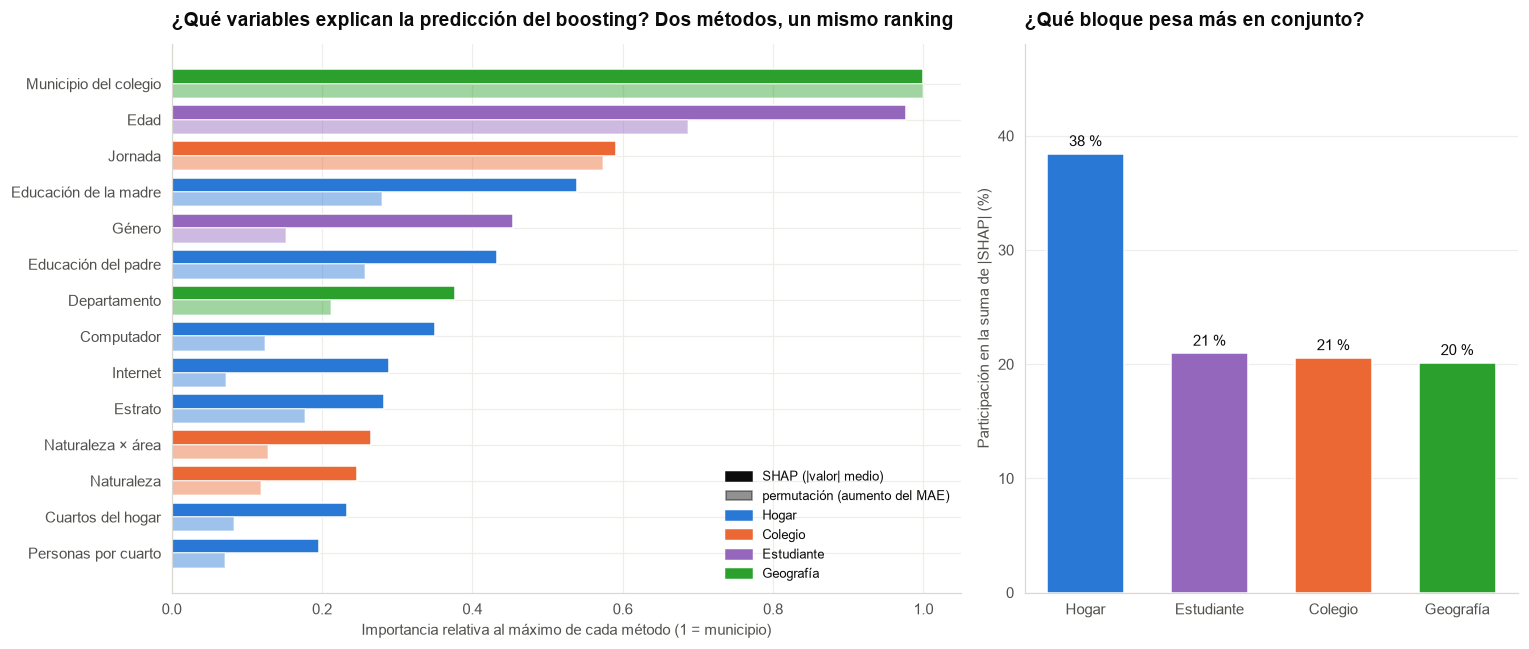

,cole_mcpio_ubicacion,edad,cole_jornada,educ_madre_ord,genero_F,educ_padre_ord,cole_depto_ubicacion,fami_tienecomputador,fami_tieneinternet,fami_estratovivienda
permutación,3.25,2.23,1.87,0.91,0.49,0.84,0.69,0.40,0.23,0.58
SHAP,8.90,8.70,5.27,4.80,4.04,3.85,3.35,3.12,2.57,2.52


In [7]:
BLOQUE = {}
for c in COLS["NOM_COLS"] + COLS["NUM_COLS"] + COLS["BIN_COLS"] + COLS["HIGH_CARD_COLS"]:
    if c in ("cole_depto_ubicacion", "cole_mcpio_ubicacion"): BLOQUE[c] = "Geografía"
    elif c.startswith("cole_") or c == "naturaleza_area": BLOQUE[c] = "Colegio"
    elif c.startswith("fami_") or c.startswith("educ_") or c in ("personas_por_cuarto", "cuestionario_incompleto"): BLOQUE[c] = "Hogar"
    else: BLOQUE[c] = "Estudiante"
NOMBRE = {"cole_mcpio_ubicacion": "Municipio del colegio", "edad": "Edad", "cole_jornada": "Jornada", "educ_madre_ord": "Educación de la madre",
          "educ_padre_ord": "Educación del padre", "cole_depto_ubicacion": "Departamento", "fami_estratovivienda": "Estrato", "genero_F": "Género",
          "naturaleza_area": "Naturaleza × área", "fami_tienecomputador": "Computador", "cole_naturaleza": "Naturaleza", "fami_cuartoshogar": "Cuartos del hogar",
          "fami_tieneinternet": "Internet", "personas_por_cuarto": "Personas por cuarto", "fami_tieneautomovil": "Automóvil", "cole_caracter": "Carácter",
          "fami_personashogar": "Personas en el hogar", "extraedad": "Extraedad", "fami_tienelavadora": "Lavadora", "cole_area_ubicacion": "Área",
          "cole_genero": "Género del colegio", "cole_calendario": "Calendario", "cole_sede_principal": "Sede principal", "cole_bilingue": "Bilingüe",
          "educ_madre_desconocida": "Educ. madre desconocida", "educ_padre_desconocida": "Educ. padre desconocida", "cuestionario_incompleto": "Cuestionario incompleto"}

imp = pd.DataFrame({"permutación": importancias["Gradient boosting"], "SHAP": shap_imp.reindex(importancias.index)})
imp_norm = imp / imp.max()
top = imp_norm.sort_values("SHAP", ascending=False).head(14)
bloques = (imp["SHAP"].groupby(pd.Series(BLOQUE)).sum() / imp["SHAP"].sum() * 100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.6, 1]})
yy = np.arange(len(top))
axes[0].barh(yy - 0.2, top["SHAP"], height=0.4, color=[BLOQUE_COLOR[BLOQUE[c]] for c in top.index], label="SHAP (|valor| medio)")
axes[0].barh(yy + 0.2, top["permutación"], height=0.4, color=[BLOQUE_COLOR[BLOQUE[c]] for c in top.index], alpha=0.45, label="permutación (aumento del MAE)")
axes[0].set_yticks(yy); axes[0].set_yticklabels([NOMBRE.get(c, c) for c in top.index], fontsize=9.5); axes[0].invert_yaxis()
axes[0].set_xlabel("Importancia relativa al máximo de cada método (1 = municipio)")
axes[0].set_title("¿Qué variables explican la predicción del boosting? Dos métodos, un mismo ranking")
axes[0].legend(handles=[Patch(color=TINTA, label="SHAP (|valor| medio)"), Patch(color=TINTA, alpha=0.45, label="permutación (aumento del MAE)")]
               + [Patch(color=v, label=k) for k, v in BLOQUE_COLOR.items()], frameon=False, fontsize=8.5, loc="lower right")
bars = axes[1].bar(bloques.index, bloques.values, color=[BLOQUE_COLOR[b] for b in bloques.index], width=0.62)
axes[1].bar_label(bars, labels=[f"{v:.0f} %" for v in bloques.values], padding=3, fontsize=10)
axes[1].set_ylim(0, bloques.max() * 1.25); axes[1].set_ylabel("Participación en la suma de |SHAP| (%)")
axes[1].set_title("¿Qué bloque pesa más en conjunto?"); axes[1].grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "story_4_importance")
plt.show()
display(imp.sort_values("SHAP", ascending=False).head(10).round(2).T)

Los dos métodos coinciden en el orden de las variables, lo que da confianza en la lectura. El **municipio del colegio** es la variable más importante por ambos criterios; le siguen la **edad**, la **jornada**, la **educación de la madre**, el **género**, la educación del padre y el departamento. Las variables del hogar (computador, internet, estrato, cuartos, personas por cuarto) tienen SHAP relativo entre 0,2 y 0,35 pero permutación mucho menor, la firma de su redundancia: el modelo las usa, pero cuando una falta puede apoyarse en las otras.

El panel derecho responde la hipótesis H1 con una cifra: el **hogar concentra el 38 %** de la contribución total del modelo, casi el doble que cada uno de los otros bloques, que se reparten en partes iguales: **estudiante 21 %, colegio 21 %, geografía 20 %**. El nivel socioeconómico del hogar es, en conjunto, el factor que más explica el puntaje, aunque ninguna de sus variables por separado supere al municipio o a la edad.

## 8. Acto 5 · Para quién falla el modelo

La última figura muestra lo que el modelo **no** logra y por qué eso importa. A la izquierda, el error absoluto del boosting por tramo de puntaje real, con la media de cada tramo anotada: el error es moderado en el centro y crece hacia los extremos. A la derecha, los **estudiantes sobresalientes que el contexto no anticipa**: cuántos obtuvieron 350 puntos o más y qué les predijo el modelo, separados por naturaleza del colegio. Es el argumento central sobre el uso responsable del modelo: describe desigualdades estructurales, pero no sabe quién las va a romper.

Figura guardada: assets\images\data\story_5_errors.png


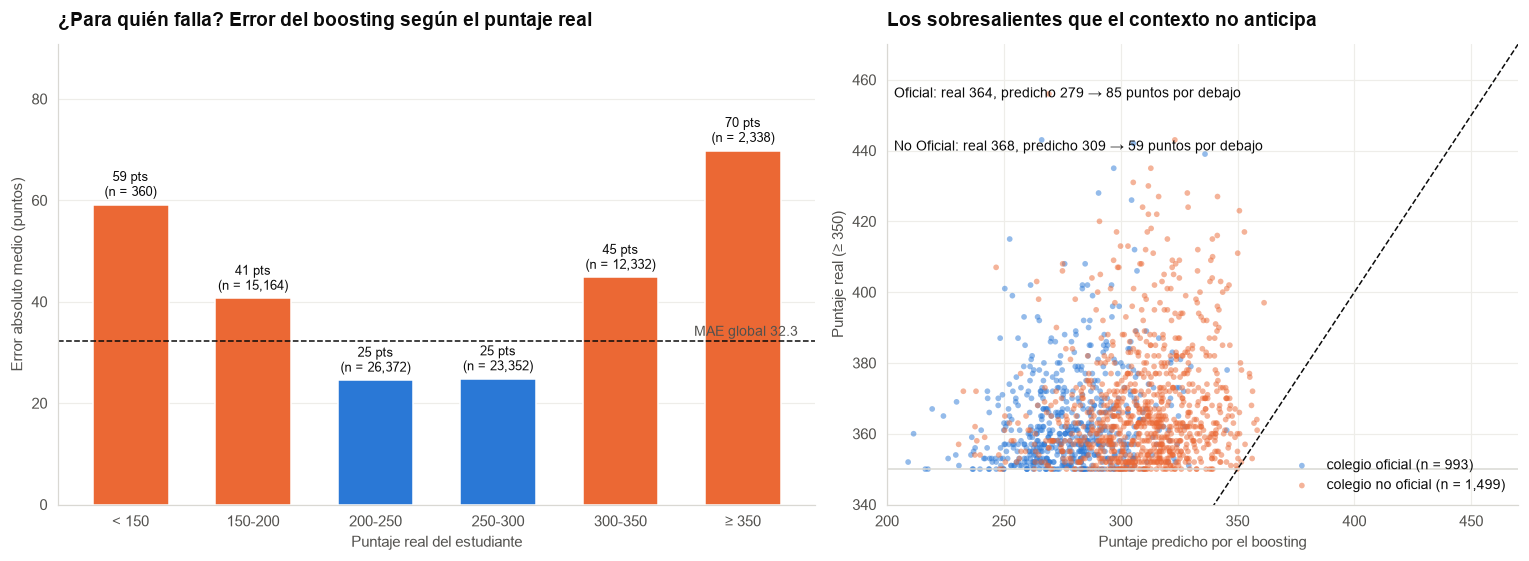

Estudiantes de prueba con 350 puntos o más: 2,492 (3.1 %); el modelo predice 350 o más para 77 de ellos


cole_naturaleza,NO OFICIAL,OFICIAL
n,"1,499.00",993.00
real,368.10,364.10
predicho,309.50,279.10
subestimación,58.70,85.00


In [8]:
err = pred.assign(error=(pred["y_real"] - pred["pred_gradient"]).abs(), residuo=pred["y_real"] - pred["pred_gradient"],
                  tramo=pd.cut(pred["y_real"], [0, 150, 200, 250, 300, 350, 500], labels=["< 150", "150-200", "200-250", "250-300", "300-350", "≥ 350"]))
err = err.join(df.loc[err.index, ["cole_naturaleza", "cole_jornada", "educ_madre_ord"]])
por_tramo = err.groupby("tramo", observed=True).agg(n=("error", "size"), mae=("error", "mean"), sesgo=("residuo", "mean"))
sobresalientes = err[err["y_real"] >= 350]
resumen_sob = sobresalientes.groupby("cole_naturaleza", observed=True).agg(n=("y_real", "size"), real=("y_real", "mean"), predicho=("pred_gradient", "mean"))
resumen_sob["subestimación"] = resumen_sob["real"] - resumen_sob["predicho"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
bars = axes[0].bar(por_tramo.index.astype(str), por_tramo["mae"], color=[C_ACCENT if m > 35 else C_HGB for m in por_tramo["mae"]], width=0.62)
axes[0].bar_label(bars, labels=[f"{m:.0f} pts\n(n = {n:,})" for m, n in zip(por_tramo["mae"], por_tramo["n"])], padding=3, fontsize=8.5)
axes[0].axhline(err["error"].mean(), color=TINTA, linestyle="--", linewidth=1); axes[0].text(5.45, err["error"].mean() + 1, f"MAE global {err['error'].mean():.1f}", ha="right", fontsize=9, color=GRIS)
axes[0].set_ylim(0, por_tramo["mae"].max() * 1.3); axes[0].set_xlabel("Puntaje real del estudiante"); axes[0].set_ylabel("Error absoluto medio (puntos)")
axes[0].set_title("¿Para quién falla? Error del boosting según el puntaje real"); axes[0].grid(axis="x", visible=False)

muestra = sobresalientes.sample(min(1500, len(sobresalientes)), random_state=RANDOM_STATE)
for nat, color in [("OFICIAL", C_HGB), ("NO OFICIAL", C_ACCENT)]:
    m = muestra[muestra["cole_naturaleza"] == nat]
    axes[1].scatter(m["pred_gradient"], m["y_real"], s=14, alpha=0.5, color=color, edgecolors="none", label=f"colegio {nat.lower()} (n = {resumen_sob.loc[nat, 'n']:,})")
axes[1].plot([200, 470], [200, 470], color=TINTA, linestyle="--", linewidth=1)
axes[1].axhline(350, color=CLARO, linewidth=1)
for nat, yy in [("OFICIAL", 455), ("NO OFICIAL", 440)]:
    r = resumen_sob.loc[nat]
    axes[1].text(203, yy, f"{nat.title()}: real {r['real']:.0f}, predicho {r['predicho']:.0f} → {r['subestimación']:.0f} puntos por debajo", fontsize=9, color=TINTA)
axes[1].set_xlim(200, 470); axes[1].set_ylim(340, 470); axes[1].set_xlabel("Puntaje predicho por el boosting"); axes[1].set_ylabel("Puntaje real (≥ 350)")
axes[1].set_title("Los sobresalientes que el contexto no anticipa"); axes[1].legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout()
save_fig(fig, "story_5_errors")
plt.show()
print(f"Estudiantes de prueba con 350 puntos o más: {len(sobresalientes):,} ({len(sobresalientes) / len(pred) * 100:.1f} %); "
      f"el modelo predice 350 o más para {(pred['pred_gradient'] >= 350).sum():,} de ellos")
display(resumen_sob.round(1).T)

El error del boosting tiene forma de U: **25 puntos** para los estudiantes entre 200 y 300 (donde están la mitad de ellos), **41** para los de 150 a 200, **45** para los de 300 a 350, **59** para los 360 estudiantes por debajo de 150 y **70** para los 2.338 que superan 350. El modelo es confiable para el estudiante típico y poco confiable para los extremos.

El panel derecho concreta el límite más importante. De los **2.492 estudiantes de prueba con 350 puntos o más (el 3,1 %), el modelo predice 350 o más solo para 77**. A los 993 que estudian en colegios oficiales les asigna en promedio 279 puntos cuando obtuvieron 364, **85 puntos por debajo**; a los 1.499 de colegios privados, 309 frente a 368, 59 por debajo. Los sobresalientes de colegios oficiales son los que el contexto anticipa peor, precisamente porque su contexto se parece al de estudiantes de puntaje medio. Esta es la razón por la que el modelo debe usarse para describir desigualdades y orientar políticas, nunca para clasificar o filtrar estudiantes individuales: cualquier uso de ese tipo penalizaría sistemáticamente al talento que surge donde menos se espera.

## 9. Resumen de resultados del proyecto

La tabla final consolida, en una sola vista, las cifras que sostienen la narrativa: tamaño del conjunto, las brechas descriptivas de la fase 1, el modelo de referencia de la fase 2 y los modelos de la fase 3 con sus tres métricas en prueba. Se guarda en `data/processed/resumen_final.csv` para el informe y la sustentación.

In [9]:
brechas_df = pd.read_csv(PROCESSED_DIR / "brechas.csv").set_index("dimensión")
resumen = pd.DataFrame([
    ("Datos", "Estudiantes del periodo 2022-4 (sin duplicados)", f"{len(df):,}"),
    ("Datos", "Variables explicativas tras la preparación", f"{len(COLS['NUM_COLS'] + COLS['BIN_COLS'] + COLS['NOM_COLS'] + COLS['HIGH_CARD_COLS'])}"),
    ("Datos", "Partición entrenamiento / validación / prueba", "70 % / 15 % / 15 %, estratificada por deciles"),
    ("Brechas", "Educación de la madre (Ninguno → Posgrado)", f"{brechas_df.loc['Educación de la madre', 'brecha']:.0f} puntos"),
    ("Brechas", "Jornada del colegio (nocturna → completa)", f"{brechas_df.loc['Jornada del colegio', 'brecha']:.0f} puntos"),
    ("Brechas", "Departamento del colegio (Chocó → Bogotá)", f"{brechas_df.loc['Departamento del colegio', 'brecha']:.0f} puntos"),
] + [("Modelos (prueba)", m, f"MAE {r['MAE']:.2f} · RMSE {r['RMSE']:.2f} · R² {r['R2']:.3f}") for m, r in prueba.iterrows()]
  + [("Interpretación", "Variables más importantes (SHAP)", ", ".join(NOMBRE.get(c, c) for c in shap_imp.sort_values(ascending=False).index[:5])),
     ("Interpretación", "Participación del bloque Hogar / Colegio / Estudiante / Geografía", " / ".join(f"{bloques.get(b, 0):.0f} %" for b in ["Hogar", "Colegio", "Estudiante", "Geografía"])),
     ("Límites", "Estudiantes de prueba a ≤ 25 puntos de su puntaje real (boosting)", f"{dentro['Gradient boosting'][0]:.1f} %"),
     ("Límites", "Subestimación media de quienes obtienen ≥ 350 puntos", f"{sobresalientes['residuo'].mean():.0f} puntos")],
    columns=["bloque", "indicador", "valor"]).set_index(["bloque", "indicador"])
resumen.to_csv(PROCESSED_DIR / "resumen_final.csv")
display(resumen)

valor
bloque           indicador                                                                                            
Datos            Estudiantes del periodo 2022-4 (sin duplicados)                                               532,792
                 Variables explicativas tras la preparación                                                         27
                 Partición entrenamiento / validación / prueba           70 % / 15 % / 15 %, estratificada por deciles
Brechas          Educación de la madre (Ninguno → Posgrado)                                                  96 puntos
                 Jornada del colegio (nocturna → completa)                                                   70 puntos
                 Departamento del colegio (Chocó → Bogotá)                                                   64 puntos
Modelos (prueba) Media (ingenuo)                                                     MAE 42.95 · RMSE 51.80 · R² 0.000
                 Ridge (referencia)                                                  MAE 34.15 · RMSE 42.17 · R² 0.338
                 Gradient boosting                                                   MAE 32.27 · RMSE 40.10 · R² 0.401
                 Random forest                                                       MAE 32.95 · RMSE 40.91 · R² 0.376
Interpretación   Variables más importantes (SHAP)                    Municipio del colegio, Edad, Jornada, Educació...
                 Participación del bloque Hogar / Colegio / Estu...                          38 % / 21 % / 21 % / 20 %
Límites          Estudiantes de prueba a ≤ 25 puntos de su punta...                                             45.8 %
                 Subestimación media de quienes obtienen ≥ 350 p...                                          69 puntos

La tabla reúne en catorce filas lo que la sustentación necesita citar: el tamaño del conjunto, las tres brechas mayores, las métricas de los cuatro modelos en prueba, las variables y bloques más importantes, y los dos límites del modelo (precisión a 25 puntos y subestimación de los sobresalientes). Queda guardada en `data/processed/resumen_final.csv`.

## 10. Guion de la narrativa para la sustentación

Diez mensajes, uno por diapositiva, con la figura que lo sostiene. Cada mensaje es una frase completa que se puede leer en voz alta.

| # | Mensaje | Figura |
|---|---|---|
| 1 | **Pregunta.** ¿Cuánto del puntaje de Saber 11 se explica por el contexto del estudiante, y qué contexto pesa más? | portada |
| 2 | **Datos.** 532.792 estudiantes del periodo 2022-4, publicados por el ICFES; la mitad de las filas del portal eran duplicados y el puntaje global es una función exacta de los puntajes por área, dos trampas que se detectaron antes de modelar. | tabla resumen |
| 3 | **La desigualdad.** La educación de la madre separa 96 puntos; la jornada, 70; el departamento, 64; la edad, 61. Todas las brechas cruzan la media nacional de 250. | `story_1_gaps` |
| 4 | **Su geografía.** La brecha regional es sobre todo socioeconómica (correlación 0,86 con el acceso a internet), pero Boyacá rinde 21 puntos por encima de su contexto y Chocó 21 por debajo. | `story_2_geography` |
| 5 | **Método.** Partición 70/15/15 estratificada, dos representaciones, Ridge como referencia, boosting y *random forest* ajustados por validación cruzada sobre una muestra y evaluados una sola vez en prueba. | diagrama de flujo |
| 6 | **Cuánto se predice.** El gradient boosting alcanza MAE de 32,3 puntos y R² de 0,40: reduce un 25 % el error de predecir la media y supera a Ridge (34,2) y al *random forest* (33,0). | `story_3_prediction` izq. |
| 7 | **Qué pesa.** Municipio, edad, jornada y educación de la madre encabezan dos métodos independientes; el hogar en conjunto aporta el 38 % de la explicación, el doble que colegio, estudiante o geografía. | `story_4_importance` |
| 8 | **Cómo pesa.** La educación de la madre vale más en sus escalones altos, dos años de extraedad cuestan 40 puntos, el hacinamiento tiene forma de U y la jornada nocturna resta 36 puntos aun controlando la edad. | `partial_dependence` |
| 9 | **Dónde falla.** El modelo comprime los extremos: al decil más alto le predice 287 cuando obtiene 344, y de 2.492 sobresalientes solo anticipa a 77; los de colegios oficiales quedan 85 puntos por debajo. | `story_5_errors` |
| 10 | **Uso responsable.** El modelo describe desigualdades estructurales y puede orientar dónde invertir (jornada, extraedad, conectividad), pero no debe usarse para decidir sobre estudiantes individuales. | cierre |

## 11. Conclusiones del proyecto

*   El proyecto respondió su pregunta con una cifra y una lista: el contexto del estudiante explica **el 40 % de la variación del puntaje global** (R² de 0,401, MAE de 32,3 puntos sobre 79.919 estudiantes de prueba), y lo que más pesa es, en este orden, el municipio del colegio, la edad, la jornada y la educación de los padres, con el **hogar como bloque dominante (38 %)**. Las tres hipótesis de la fase 1 quedaron respaldadas.

*   Las cinco figuras finales cuentan la historia completa en puntos de la escala: brechas de 55 a 96 puntos según el contexto, una brecha regional que es socioeconómica en un 86 % pero con departamentos que rinden hasta 21 puntos por encima o por debajo de lo esperado, un modelo que reduce el error un 25 %, dos métodos de interpretación que coinciden, y un límite claro en los extremos.

*   Ese límite es también la conclusión ética del proyecto: el modelo anticipa a solo 77 de los 2.492 estudiantes sobresalientes y subestima en 85 puntos a los que vienen de colegios oficiales. Sirve para describir desigualdades y orientar decisiones de política (jornada completa, extraedad, conectividad), no para evaluar o filtrar personas.

*   Metodológicamente, el valor del trabajo estuvo tanto en lo que se evitó como en lo que se construyó: deduplicar antes de particionar, excluir los puntajes por área, conservar los faltantes como información, ajustar hiperparámetros sobre una muestra y verificar la aditividad de SHAP antes de interpretar. Cada decisión está documentada en los cuatro cuadernos, es reproducible desde la copia pública del dataset en Kaggle y corre en Google Colab sin instalación.

*   Como trabajo futuro quedan tres caminos: extender el análisis a varios periodos para ver si las brechas cambian en el tiempo, incorporar información agregada por colegio (tamaño, resultados históricos) como variables de contexto, y modelar los puntajes por área por separado para saber si las mismas variables pesan igual en matemáticas que en lectura crítica.